**Nombre completo: Carlos alberto hernandez**

**Grupo:002**

**Fecha:11/10/2026**

---

# Variables aleatorias discretas
**Simulación de Sistemas · Sesión del 7 de octubre de 2026 · Segunda hora**

Hasta ahora generamos **tiempos**. Hoy generamos **conteos**: ¿cuántos clientes?

Cuatro distribuciones, un mismo ejemplo: cada minuto llega un cliente a la ventanilla con probabilidad `p = 0.3`.

| Distribución | Pregunta |
|---|---|
| Bernoulli | ¿Llega un cliente este minuto? (0 o 1) |
| Binomial | ¿Cuántos llegan en 10 minutos? (0 a 10) |
| Geométrica | ¿Cuántos minutos hasta el primer cliente? (1, 2, 3…) |
| Poisson | ¿Cuántos llegan en un periodo, sin tope? (0, 1, 2…) |

Solo usamos `random` y `math`. Si no te salen exactamente mis cifras, es normal: es azar y depende del orden en que corras las celdas.

In [ ]:
import math
import random

random.seed(7)
P = 0.3
N = 1000   # corridas para comparar con la teoría

## Bernoulli: ¿llega un cliente este minuto?
Un `if` al azar con dos salidas: 1 si llega, 0 si no.

**Predice:** con `p = 0.3` y 1000 minutos, ¿en cuántos llega un cliente?

In [ ]:
def bernoulli(p):
    if random.random() < p:
        return 1
    return 0


valores = [bernoulli(P) for _ in range(N)]
print("llegaron en", sum(valores), "de", N, "minutos")

## Binomial: ¿cuántos llegan en 10 minutos?
Un `for` que suma 10 Bernoulli. Cada vuelta es un minuto.

**Predice:** con `p = 0.3` en 10 minutos, ¿cuántos esperas? ¿Puede salir 10?

In [ ]:
def binomial(n, p):
    total = 0
    for _ in range(n):
        total += bernoulli(p)
    return total


valores_bin = [binomial(10, P) for _ in range(N)]
print(valores_bin[:15])

## Geométrica: ¿cuántos minutos hasta el primer cliente?
Un `while` que repite el Bernoulli hasta que sale éxito y va contando los intentos.

Aquí contamos **desde 1**: el minuto en que llega el cliente cuenta. Hay libros que cuentan solo los minutos sin cliente y empiezan en 0.

**Predice:** con `p = 0.3`, ¿cuántos minutos esperas en promedio? ¿Puede ser 1?

In [ ]:
def geometrica(p):
    minutos = 1
    while bernoulli(p) == 0:
        minutos += 1
    return minutos


valores_geo = [geometrica(P) for _ in range(N)]
print(valores_geo[:15])

## Poisson: ¿cuántos llegan en un periodo?
Es la misma ventanilla de la primera hora: sumamos **tiempos entre llegadas** (exponenciales) y contamos cuántos caben en el periodo.

Aquí `lam = 0.3` clientes por minuto, así que en 10 minutos llegan 3 en promedio.

`p` y `lam` **no son lo mismo**: `p` es la probabilidad de que llegue un cliente en un minuto (va de 0 a 1); `lam` es cuántos clientes llegan por minuto en promedio. Usamos 0.3 en ambos para poder comparar.

In [ ]:
def exponencial(media):
    u = random.random()
    return -math.log(1 - u) * media


def entre_llegadas(lam):
    return exponencial(1 / lam)


def clientes_en(minutos, lam):
    t = entre_llegadas(lam)
    n = 0
    while t <= minutos:
        n += 1
        t += entre_llegadas(lam)
    return n


valores_poi = [clientes_en(10, 0.3) for _ in range(N)]
print(valores_poi[:15])

## Teórico vs simulado
Lo que dice la fórmula contra lo que sale al correr el código. Frecuencias en porcentaje.

In [ ]:
def t_bernoulli(k, p):
    return p if k == 1 else 1 - p


def t_binomial(k, n, p):
    return math.comb(n, k) * p**k * (1 - p) ** (n - k)


def t_geometrica(k, p):
    return (1 - p) ** (k - 1) * p


def t_poisson(k, lam):
    return math.exp(-lam) * lam**k / math.factorial(k)


def tabla(titulo, valores, ks, teorica):
    print(titulo)
    print(f"{'k':>3} {'simulado %':>11} {'teórico %':>10}")
    for k in ks:
        sim = 100 * valores.count(k) / len(valores)
        print(f"{k:>3} {sim:>11.1f} {100 * teorica(k):>10.1f}")
    print()


tabla("Bernoulli (p=0.3)", valores, [0, 1], lambda k: t_bernoulli(k, P))
tabla("Binomial (n=10, p=0.3)", valores_bin, range(0, 9), lambda k: t_binomial(k, 10, P))
tabla("Geométrica (p=0.3)", valores_geo, range(1, 10), lambda k: t_geometrica(k, P))
tabla("Poisson (10 min, lam=0.3)", valores_poi, range(0, 9), lambda k: t_poisson(k, 3.0))

## Promedios y varianzas con muchas corridas
Con 1000 corridas las frecuencias se mueven; con 200 000 los promedios se acercan mucho a la teoría. (Tarda unos segundos.)

In [ ]:
M = 200000


def media_var(f):
    xs = [f() for _ in range(M)]
    m = sum(xs) / M
    var = sum((x - m) ** 2 for x in xs) / M
    return round(m, 3), round(var, 3)


print("bernoulli  esperado 0.3, 0.21    :", media_var(lambda: bernoulli(P)))
print("binomial   esperado 3.0, 2.1     :", media_var(lambda: binomial(10, P)))
print("geometrica esperado 3.333, 7.778 :", media_var(lambda: geometrica(P)))
print("poisson    esperado 3.0, 3.0     :", media_var(lambda: clientes_en(10, 0.3)))

**Para pensar:**
- Binomial (10, 0.3) y Poisson (media 3) tienen el mismo promedio. ¿Qué cambia? *(La binomial tiene tope en 10; la Poisson no. Y la Poisson se dispersa más: varianza 3 contra 2.1.)*
- Quiero saber cuántos clientes llegan en una hora. ¿Cuál uso?
- Quiero saber cuántos minutos pasan hasta que llega el primer cliente del día. ¿Cuál uso?

## Actividad 8 — tu turno
1. Genera las cuatro distribuciones con tu propio código.
2. Compara las frecuencias simuladas contra las teóricas.
3. Resuelve los 5 ejercicios que siguen.
4. Entrega este notebook (`.ipynb`) en tu repo de GitHub; el link va en la plataforma.

In [ ]:
# Tu trabajo aquí

## Ejercicios de la Actividad 8
Siempre en la ventanilla: llega un cliente cada minuto con `p = 0.3` (o `lam = 0.3` por minuto). Usa las funciones de arriba. En cada ejercicio, **escribe tu predicción** en un comentario antes de correr.

1. **Binomial.** En 10 minutos, ¿cuál es la probabilidad de que lleguen **5 o más** clientes? Estímala con simulación y compárala con la teoría (suma `t_binomial` para k = 5 a 10).
2. **Geométrica.** ¿Cuál es la probabilidad de que el primer cliente tarde **más de 5 minutos** en llegar? Estímala con simulación y compárala con la teoría.
3. **Poisson.** En 10 minutos, ¿cuál es la probabilidad de que **no llegue ningún cliente**? Estímala con simulación y compárala con `t_poisson(0, 3.0)`.
4. **Decisión.** Un cajero atiende máximo **4 clientes** cada 10 minutos. Con Poisson, ¿en qué porcentaje de los periodos llegan más de 4? Si pasa de 10 %, ¿abrirías una segunda ventanilla? Justifica en una línea.
5. **Para pensar.** Repite el ejercicio 1 con 100, 1000 y 100 000 corridas, tres veces cada una. ¿Qué pasa con la variación entre repeticiones? ¿Cuántas corridas usarías para dar el número?

Media simulada: 2.9922
Varianza simulada: 2.0965391600000003
Media teórica: 3.0
Varianza teórica: 2.0999999999999996


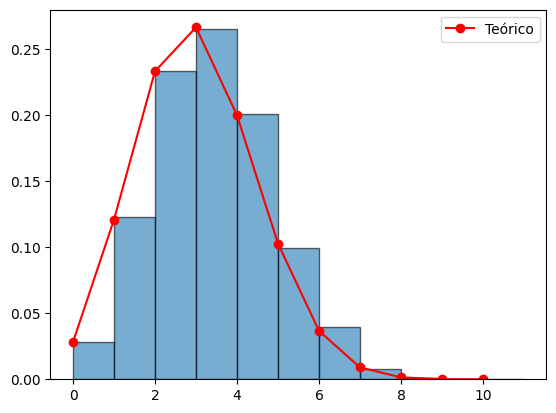

In [1]:
# Ejercicio 1
# Mi predicción: ...
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

# Parámetros
n, p = 10, 0.3
muestras = np.random.binomial(n, p, 10000)

print("Media simulada:", np.mean(muestras))
print("Varianza simulada:", np.var(muestras))
print("Media teórica:", n*p)
print("Varianza teórica:", n*p*(1-p))

plt.hist(muestras, bins=range(n+2), density=True, alpha=0.6, edgecolor="black")
x = np.arange(0, n+1)
plt.plot(x, binom.pmf(x, n, p), 'ro-', label="Teórico")
plt.legend(); plt.show()


Media simulada: 4.0277
Varianza simulada: 4.04213271
Media/Varianza teórica: 4


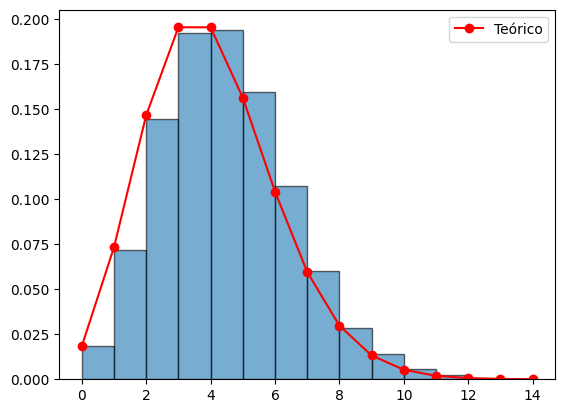

In [2]:
# Ejercicio 2
# Mi predicción: ...
from scipy.stats import poisson

lam = 4
muestras = np.random.poisson(lam, 10000)

print("Media simulada:", np.mean(muestras))
print("Varianza simulada:", np.var(muestras))
print("Media/Varianza teórica:", lam)

plt.hist(muestras, bins=range(0,15), density=True, alpha=0.6, edgecolor="black")
x = np.arange(0,15)
plt.plot(x, poisson.pmf(x, lam), 'ro-', label="Teórico")
plt.legend(); plt.show()


Media simulada: 4.0041
Varianza simulada: 12.262683189999999
Media teórica: 4.0
Varianza teórica: 12.0


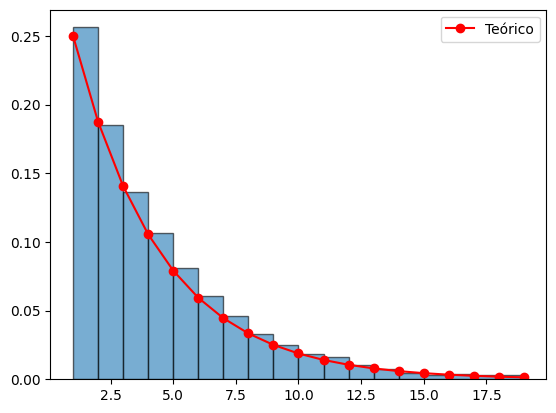

In [3]:
# Ejercicio 3
# Mi predicción: ...
from scipy.stats import geom

p = 0.25
muestras = np.random.geometric(p, 10000)

print("Media simulada:", np.mean(muestras))
print("Varianza simulada:", np.var(muestras))
print("Media teórica:", 1/p)
print("Varianza teórica:", (1-p)/(p**2))

plt.hist(muestras, bins=range(1,20), density=True, alpha=0.6, edgecolor="black")
x = np.arange(1,20)
plt.plot(x, geom.pmf(x, p), 'ro-', label="Teórico")
plt.legend(); plt.show()


Media simulada: 3.4758
Varianza simulada: 2.9148143600000003
Media teórica: 3.5
Varianza teórica: 2.9166666666666665


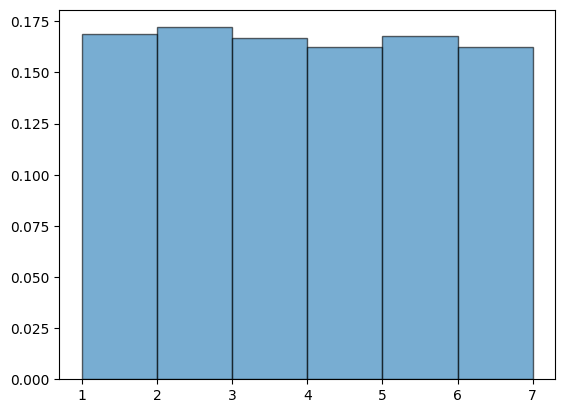

In [4]:
# Ejercicio 4
# Mi predicción: ...
from scipy.stats import randint

a, b = 1, 6  # como un dado
muestras = np.random.randint(a, b+1, 10000)

print("Media simulada:", np.mean(muestras))
print("Varianza simulada:", np.var(muestras))
print("Media teórica:", (a+b)/2)
print("Varianza teórica:", ((b-a+1)**2 - 1)/12)

plt.hist(muestras, bins=range(a, b+2), density=True, alpha=0.6, edgecolor="black")
plt.show()


Media simulada: 1.7424
Varianza simulada: 0.91544224
Media teórica: 1.75
Varianza teórica: 0.8980263157894737


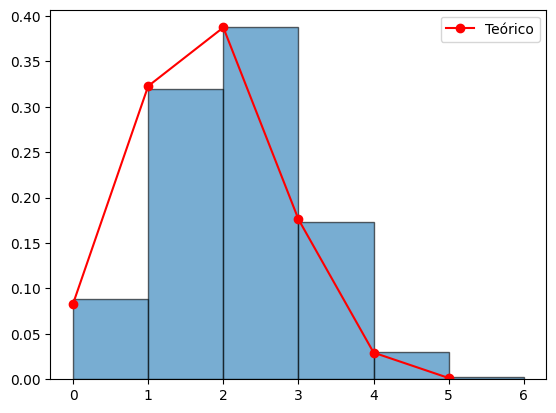

In [5]:
# Ejercicio 5
# Mi predicción: ...
from scipy.stats import hypergeom

# Supongamos una urna con 20 bolas: 7 rojas y 13 negras
M, n, N = 20, 7, 5  # población total, éxitos en población, tamaño de muestra
muestras = hypergeom.rvs(M, n, N, size=10000)

print("Media simulada:", np.mean(muestras))
print("Varianza simulada:", np.var(muestras))
print("Media teórica:", N*(n/M))
print("Varianza teórica:", N*(n/M)*(1-n/M)*((M-N)/(M-1)))

plt.hist(muestras, bins=range(0,N+2), density=True, alpha=0.6, edgecolor="black")
x = np.arange(0,N+1)
plt.plot(x, hypergeom.pmf(x, M, n, N), 'ro-', label="Teórico")
plt.legend(); plt.show()
